# 03. 상담 예제 2 — "해외송금이 아직 도착하지 않았어요" (tool retry loop)

두 번째 상담 예제입니다. 이번에는 질문에 정보가 충분하지만(송금 번호·금액 포함), **첫 번째 tool이 시스템 오류(tool_error)를 반환**합니다. agent는 D6(tool 결과 검토)에서 오류를 읽고 `try_alternative`를 판정해 **다른 tool로 재시도**하는 recursive loop를 돕니다.

예상 경로:
```
D1 -> D2(transfers) -> D5(info_sufficient) -> D3(track_transfer) -> tool_error
-> D6(try_alternative) -> D3(대체 tool, 실패 tool 제외) -> 성공 -> D6(goal_met)
-> 요약 -> D7(no_risk) -> D4(resolve) -> 최종 응답
```

실제 운영에서 흔한 "일시 오류 -> 자동 복구" 흐름입니다. 재시도 loop가 돌면 판단 횟수가 9회까지 늘어나므로 판단 latency의 누적 효과가 더 잘 보입니다.

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common 경로 (repo 내 상대 위치)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[2]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script:", sc["script"])   # tool_outcomes: [tool_error, success]

시나리오: 시스템 오류 -> tool retry loop
고객 질문: 어제 오후에 보낸 해외송금이 아직 수취인에게 도착하지 않았어요. 송금 번호는 TR-20261026-8841, 금액은 USD 2,000입니다. 확인해 주세요.
script: {'vague': False, 'clarify_reply': None, 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['tool_error', 'success'], 'risk_flag': False, 'kyc_result': None}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): 되묻기 없이 바로 tool로 진행하지만, 첫 tool이 실패해 **tool_step의 self-loop(재시도)** 를 한 바퀴 돕니다. 같은 노드가 두 번 실행되는 것을 STEP 출력에서 확인하세요.

배정 상담팀(빨간 표시): **transfers(이체/송금)** — 해외송금 추적이므로 transfers 팀 tool(track_transfer 등)로 처리됩니다.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `01_build_agent.ipynb` 참조).


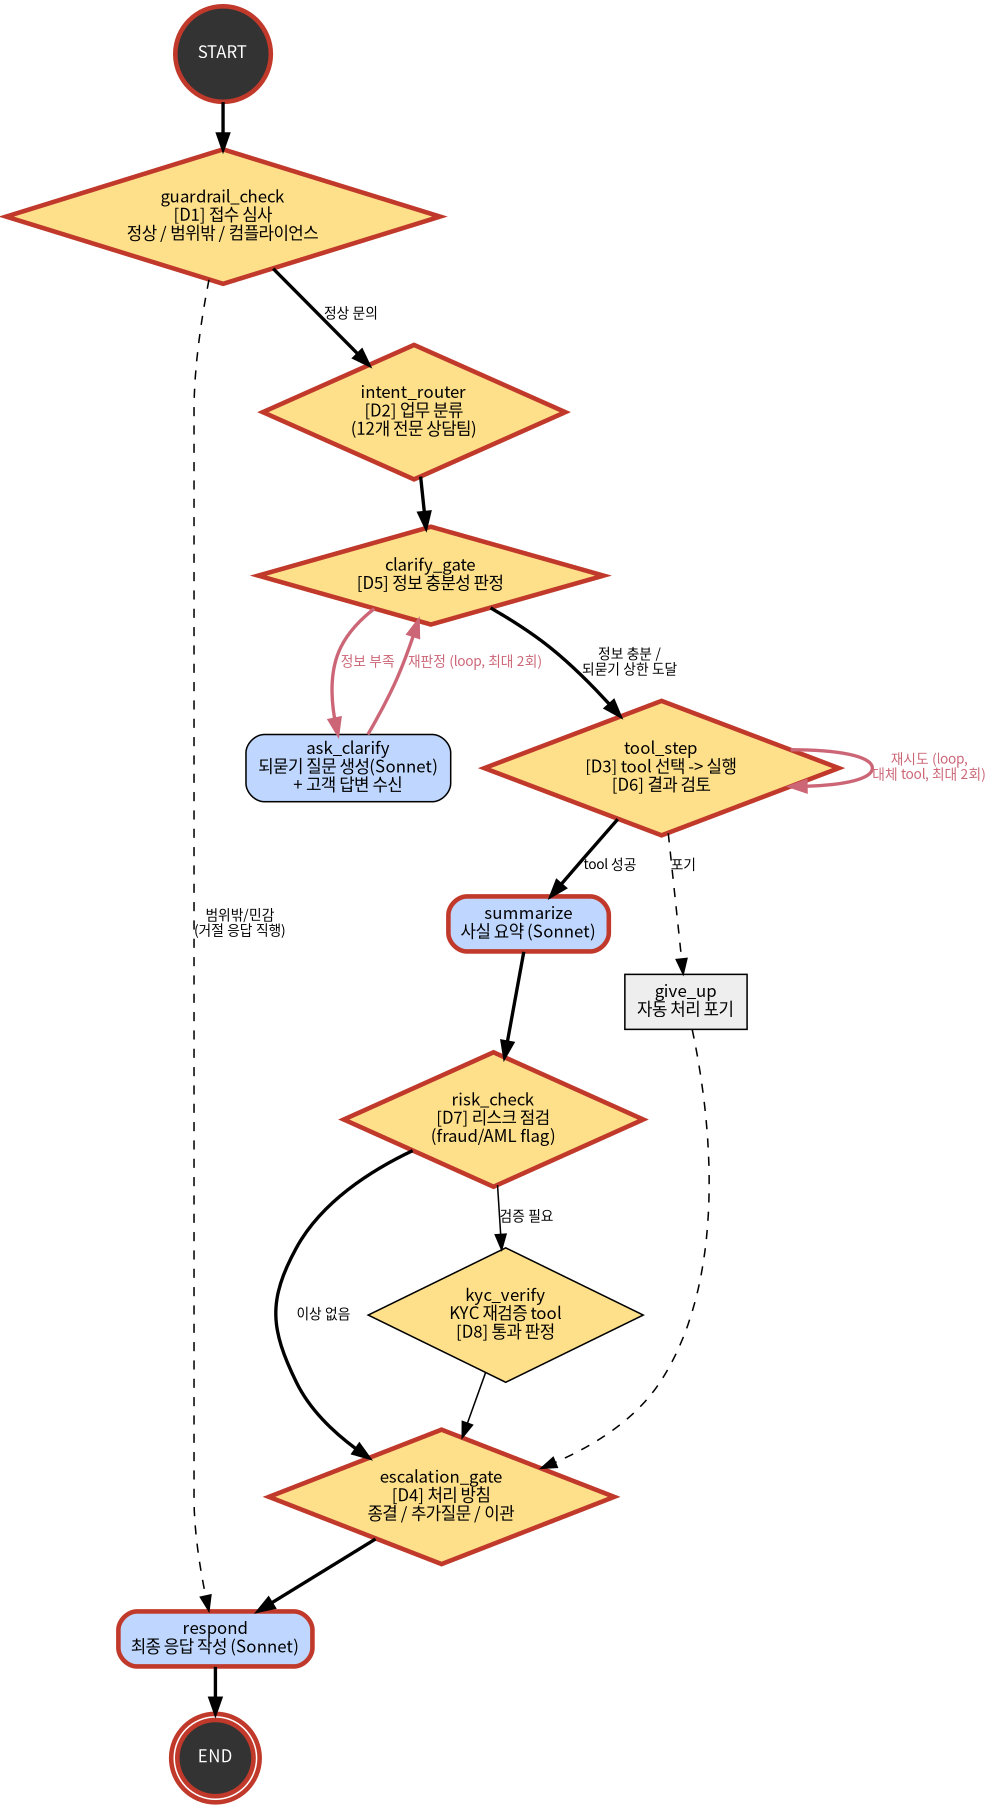

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[2], show_teams=True, width=760)

## ① Haiku 4.5 판단으로 실행

STEP 출력에서 tool_step이 **두 번** 나타나는 것(실패 -> 대체 tool 재시도)과, 두 번째 D3 판정 때 "Already tried (failed)" 정보가 반영되는 것을 확인하세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 어제 오후에 보낸 해외송금이 아직 수취인에게 도착하지 않았어요. 송금 번호는 TR-20261026-8841, 금액은 USD 2,000입니다. 확인해 주세요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (936ms)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> transfers   (879ms)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (646ms)

STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> track_transfer   (624ms)
      tool 실행: track_transfer   (0.0ms)
      판정[D6] -> try_alternative   (655ms)

STEP 5 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> transfer_info   (1,461ms)
      tool 실행: transfer_info   (0.0ms)
      판정[D6] -> goal_met   (667ms)

STEP 6 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (3,986ms)
      요약(첫 줄): Based on the tool result, I can only extract the following facts:

STEP 7 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유

## ② SGLang(Qwen3-VL-8B) 판단으로 실행

In [4]:
res_sglang = W.run_verbose(graphs["SGLang"], sc["question"], sc["script"], "SGLang")


[SGLang] 고객: 어제 오후에 보낸 해외송금이 아직 수취인에게 도착하지 않았어요. 송금 번호는 TR-20261026-8841, 금액은 USD 2,000입니다. 확인해 주세요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (54ms, confidence 1.000)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> transfers   (34ms, confidence 1.000)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (33ms, confidence 1.000)

STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> track_transfer   (33ms, confidence 1.000)
      tool 실행: track_transfer   (0.0ms)
      판정[D6] -> try_alternative   (35ms, confidence 1.000)

STEP 5 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> transfer_info   (33ms, confidence 1.000)
      tool 실행: transfer_info   (0.0ms)
      판정[D6] -> goal_met   (34ms, confidence 0.965)

STEP 6 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (4,288ms)
      요약(첫 줄): Bas

## ③ 수행시간 비교

In [5]:
W.compare(res_haiku, res_sglang)

| 지표 | Haiku | SGLang |
|---|---:|---:|
| 결정 횟수 | 9 | 9 |
| **결정 latency 합계** | **7,241ms** | **328ms** |
| 생성(LLM) latency | 9,616ms | 10,044ms |
| e2e | 16,867ms | 10,379ms |

**결정 계층 속도 차이: 22.1x** (e2e 단축 6,488ms)

**결정별 latency**

| 노드 | 결정 | Haiku | SGLang | 판정 label |
|---|---|---:|---:|---|
| guardrail_check | D1 | 936ms | 54ms | in_scope (동일) |
| intent_router | D2 | 879ms | 34ms | transfers (동일) |
| clarify_gate | D5 | 646ms | 33ms | info_sufficient (동일) |
| tool_select | D3 | 624ms | 33ms | track_transfer (동일) |
| tool_review | D6 | 655ms | 35ms | try_alternative (동일) |
| tool_select | D3 | 1,461ms | 33ms | transfer_info (동일) |
| tool_review | D6 | 667ms | 34ms | goal_met (동일) |
| risk_check | D7 | 667ms | 37ms | no_risk (동일) |
| escalation_gate | D4 | 706ms | 35ms | Haiku=human_handoff / SGLang=clarify |

**관찰 포인트**
- D6은 "tool의 JSON 결과를 읽고 상황을 판단"하는 결정입니다 — 분류보다 어려운 유형인데도 두 backend가 같은 결론(try_alternative -> goal_met)에 도달했는지 확인하세요.
- 판단이 9회로 늘면서 Haiku arm의 판단 누적 시간이 5-6초에 달합니다. loop가 많은 agent일수록 decision layer의 가치가 커지는 이유입니다.
- 다음: `04_scenario3_risk_kyc.ipynb` — 이상거래 모니터링 flag와 KYC 재검증 sub-flow.